# HS4002 Week 9

## Principal components analysis

A principal component is a linear combination of the variables. PCA reduces them to a smaller number of uncorrelated components.

The worked example uses five GSS variables: income, occupational prestige, education, number of children, and age. Each is scaled to mean 0 and SD 1. We fit the model with `sklearn.decomposition.PCA` and draw the scree plot with `plotnine`.


In [1]:
# !pip install pandas numpy plotnine scikit-learn statsmodels

import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')


In [4]:
raw_df = pd.read_csv("gss2022_mini2.csv")

chosen_variables = [
	'id', 'age', 'happy', 'yrlvmus', 'yrartxbt', 'yrmovie', 'yrcreat',
	'income16', 'prestg10', 'degree', 'biokids', 'educ'
]
df = raw_df[chosen_variables].copy()

income_map = {
	1: 500,    2: 2000,   3: 3500,   4: 4500,   5: 5500,   6: 6500,
	7: 7500,   8: 9000,   9: 11250,  10: 13750, 11: 16250, 12: 18750,
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 45000,
	19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 24: 140000,
	25: 160000, 26: 250000
}
df['income_cont'] = df['income16'].map(income_map)

df['binary_lvmus']  = (df['yrlvmus']  == 1).astype(int)
df['binary_artxbt'] = (df['yrartxbt'] == 1).astype(int)
df['binary_movie']  = (df['yrmovie']  == 1).astype(int)
df['binary_creat']  = (df['yrcreat']  == 1).astype(int)
df['ba_binary']     = (df['degree'] >= 3).astype(int)
df['happy_bin']     = (df['happy'] <= 2).astype(int)


# Steps

1. Choose the variables.
2. Scale each one to mean 0 and SD 1.
3. Fit the PCA.
4. Decide how many components to keep. The scree plot is the guide. There is no single rule.
5. Read the loadings.
6. Use the components in a plot or a regression.


## 1. Choose the variables

`income_cont` is income in dollars. `prestg10` is occupational prestige. `educ` is years of schooling. `biokids` is the number of children. `age` is age in years.


In [5]:
cols = ["income_cont", "prestg10", "educ", "biokids", "age"]
work = df.dropna(subset=cols).copy()
work[cols].describe().round(1)


,income_cont,prestg10,educ,biokids,age
count,1056.0,1056.0,1056.0,1056.0,1056.0
mean,86222.1,46.8,14.9,1.6,50.9
std,72378.7,13.3,2.7,1.5,17.3
min,500.0,17.0,2.0,0.0,18.0
25%,32500.0,36.0,13.0,0.0,36.0
50%,67500.0,47.0,15.0,2.0,51.0
75%,120000.0,59.0,16.0,2.0,66.0
max,250000.0,80.0,20.0,11.0,89.0


## 2--3. Scale, then fit

`StandardScaler` subtracts the mean and divides by the standard deviation. Without that step, income, which is measured in dollars, would dominate the first component.


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

prop = pca.explained_variance_ratio_
print(pd.DataFrame({
    "Standard deviation": pca.explained_variance_ ** 0.5,
    "Proportion of variance": prop,
    "Cumulative proportion": prop.cumsum(),
}, index=["PC1", "PC2", "PC3", "PC4", "PC5"]).T.round(3))


                          PC1    PC2    PC3    PC4    PC5
Standard deviation      1.368  1.127  0.882  0.781  0.689
Proportion of variance  0.374  0.254  0.155  0.122  0.095
Cumulative proportion   0.374  0.628  0.783  0.905  1.000


PC1 accounts for 37.4 per cent of the variance. The first two components together account for 62.8 per cent.


## 4. Loadings

In `sklearn`, each row of `pca.components_` is one component. Transposing it puts the variables in the rows, so each column is a component. A large loading means that variable defines that component.


In [7]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
)
print(loadings.round(3))


               PC1    PC2    PC3    PC4    PC5
income_cont  0.524  0.009 -0.517  0.676 -0.030
prestg10     0.592  0.095  0.042 -0.457 -0.656
educ         0.594 -0.112  0.209 -0.268  0.721
biokids     -0.098  0.710 -0.560 -0.351  0.223
age          0.109  0.689  0.612  0.373 -0.022


How would you describe PC1 and PC2?

PC1 loads on income, occupational prestige, and education. PC2 loads on number of children and age.


## 5. How many components?

Look for an elbow in the scree plot: the point where adding another component buys little extra variance.


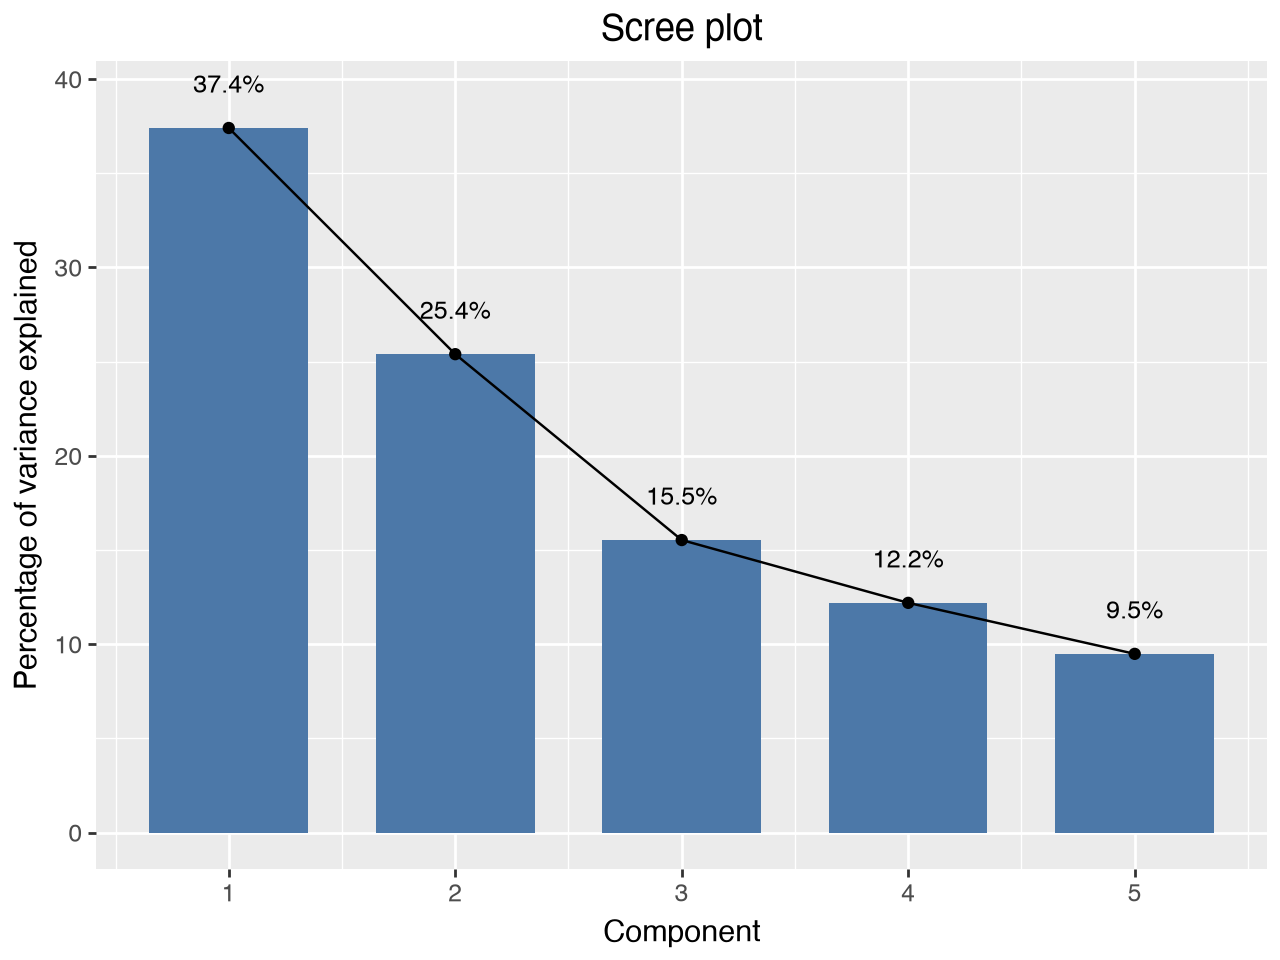

In [8]:
scree = pd.DataFrame({
    "component": range(1, 6),
    "percent": pca.explained_variance_ratio_ * 100,
})
scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(x="Component", y="Percentage of variance explained", title="Scree plot")
)


## 6. Use the components

The first two components locate each person in a plane. Colour the points by whether the person has a BA. A BA was not one of the five variables in the PCA, so the colour is a separate fact about the person.


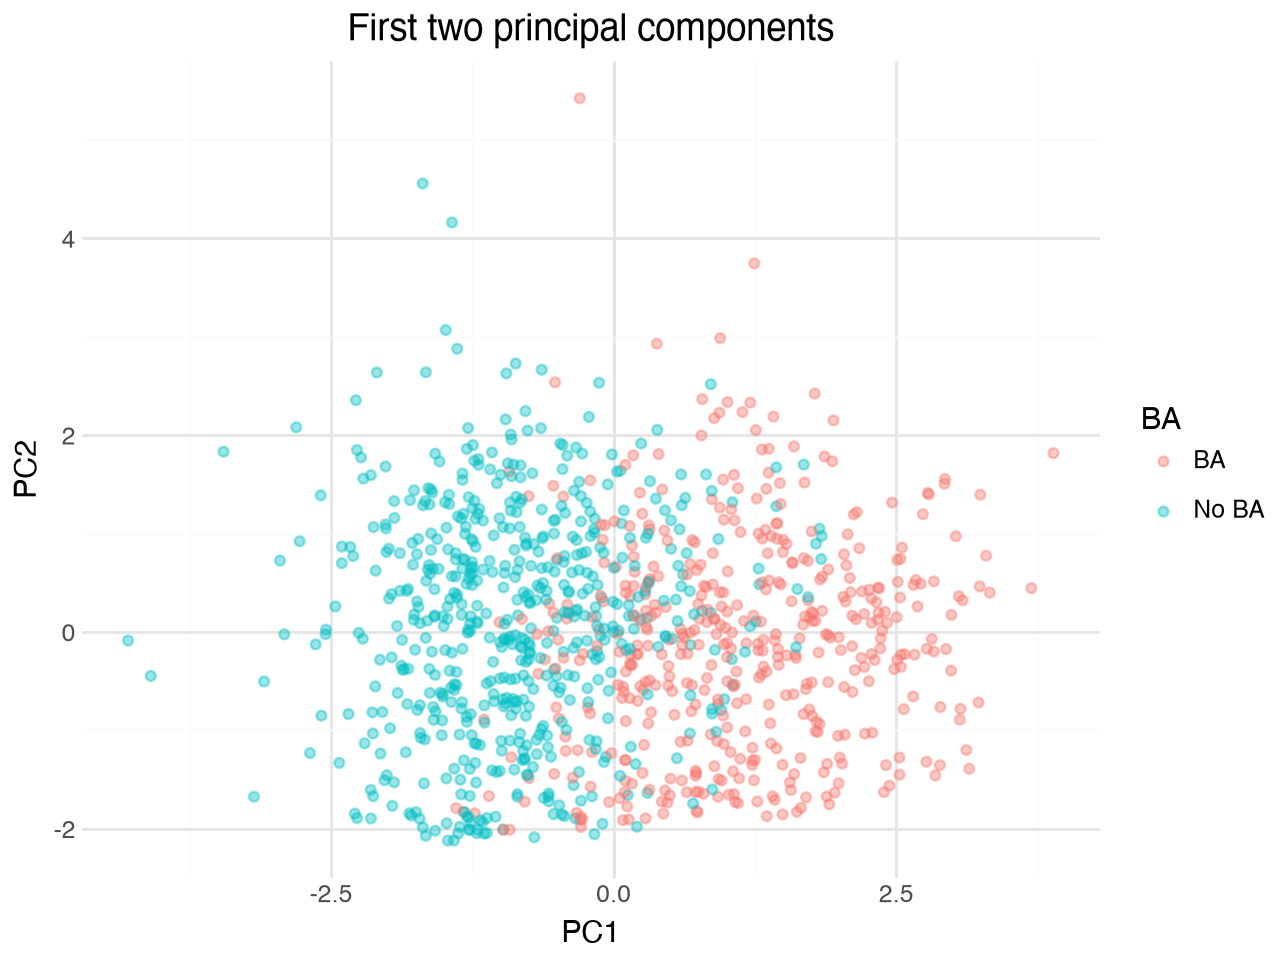

In [9]:
scores = pca.transform(X)
plot_df = work.copy()
plot_df["PC1"] = scores[:, 0]
plot_df["PC2"] = scores[:, 1]
plot_df["BA"] = np.where(plot_df["ba_binary"] == 1, "BA", "No BA")

(
    ggplot(plot_df, aes("PC1", "PC2", color="BA"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(x="PC1", y="PC2", title="First two principal components")
)


## 7. A linear model for PC1

PC1 is the dependent variable. `ba_binary` is the independent variable: 1 is a BA, 0 is not.

This is an OLS model. The coefficient on `ba_binary` is the expected difference in PC1 between a person with a BA and a person without one.


In [10]:

import statsmodels.formula.api as smf

ols_pc1 = smf.ols('PC1 ~ ba_binary', data=plot_df).fit()

print(ols_pc1.summary())

                            OLS Regression Results                            
Dep. Variable:                    PC1   R-squared:                       0.508
Model:                            OLS   Adj. R-squared:                  0.508
Method:                 Least Squares   F-statistic:                     1090.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          9.80e-165
Time:                        00:13:17   Log-Likelihood:                -1453.9
No. Observations:                1056   AIC:                             2912.
Df Residuals:                    1054   BIC:                             2922.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.8650      0.039    -21.911      0.0

The OLS regression indicates that individuals with at least a Bachelor's degree have an average PC1 score approximately 1.964 units higher than individuals without one (p < 0.001). Since PC1 primarily captures income, occupational prestige, and education, this suggests that BA holders generally score higher on this socioeconomic component. The model explains 50.8% of the variance in PC1 (R² = 0.508).

## 8. A logit model for a BA

`ba_binary` is now the dependent variable, and PC1 and PC2 are the independent variables. `ba_binary` is coded 0 or 1, so we fit a logit.

The coefficient is the expected change in the log odds of having a BA. Exponentiating it gives the factor by which the odds change.


In [11]:

logit_ba = smf.logit('ba_binary ~ PC1 + PC2', data=plot_df).fit()

print(logit_ba.summary())

# Calculate odds ratios
print(np.exp(logit_ba.params))

Optimization terminated successfully.
         Current function value: 0.340435
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              ba_binary   No. Observations:                 1056
Model:                          Logit   Df Residuals:                     1053
Method:                           MLE   Df Model:                            2
Date:                Wed, 21 Oct 2026   Pseudo R-squ.:                  0.5037
Time:                        00:13:37   Log-Likelihood:                -359.50
converged:                       True   LL-Null:                       -724.43
Covariance Type:            nonrobust   LLR p-value:                3.259e-159
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3769      0.095     -3.972      0.000      -0.563      -0.191
PC1            2.0936      0.

The logistic regression indicates that PC1 is positively and significantly associated with having at least a Bachelor's degree (β = 2.094, p < 0.001). A one-unit increase in PC1 is associated with 8.114 times the odds of having a BA, holding PC2 constant.

Conversely, PC2 has a negative and statistically significant coefficient (β = −0.392, p < 0.001). A one-unit increase in PC2 is associated with approximately 32.4% lower odds of having a BA, holding PC1 constant.

The model has a pseudo R² of 0.504, indicating substantial improvement in fit relative to the null model.

# Independent exercise

Use `happy_bin` as the dependent variable. Build the components from `income_cont`, `prestg10`, `educ`, `age`, and the four cultural-participation indicators (`binary_lvmus`, `binary_artxbt`, `binary_movie`, `binary_creat`). Leave `happy_bin` out of the PCA.

1. Scale each variable to mean 0 and SD 1, then fit a PCA.
2. Print the proportion of variance and the cumulative proportion.
3. Draw a scree plot with `plotnine` and decide how many components to keep.
4. Print the loadings and describe the first two components.
5. Scatter PC1 against PC2, coloured by happiness.
6. Fit a logit of `happy_bin` on the components you kept, and interpret the coefficients.


In [12]:
# Choose variables for PCA
cols_happy = [
    'income_cont', 'prestg10', 'educ', 'age',
    'binary_lvmus', 'binary_artxbt',
    'binary_movie', 'binary_creat'
]

# Remove missing values for the required variables
work_happy = df.dropna(subset=cols_happy + ['happy_bin']).copy()

# Standardise the variables
X_happy = StandardScaler().fit_transform(work_happy[cols_happy])

# Fit the PCA
pca_happy = PCA().fit(X_happy)

In [13]:

prop_happy = pca_happy.explained_variance_ratio_

print(pd.DataFrame({
    "Proportion of variance": prop_happy,
    "Cumulative proportion": prop_happy.cumsum()
}, index=[f"PC{i}" for i in range(1, 9)]).T.round(3))

                          PC1    PC2    PC3   PC4    PC5    PC6    PC7    PC8
Proportion of variance  0.323  0.211  0.126  0.09  0.079  0.065  0.063  0.044
Cumulative proportion   0.323  0.534  0.660  0.75  0.828  0.893  0.956  1.000


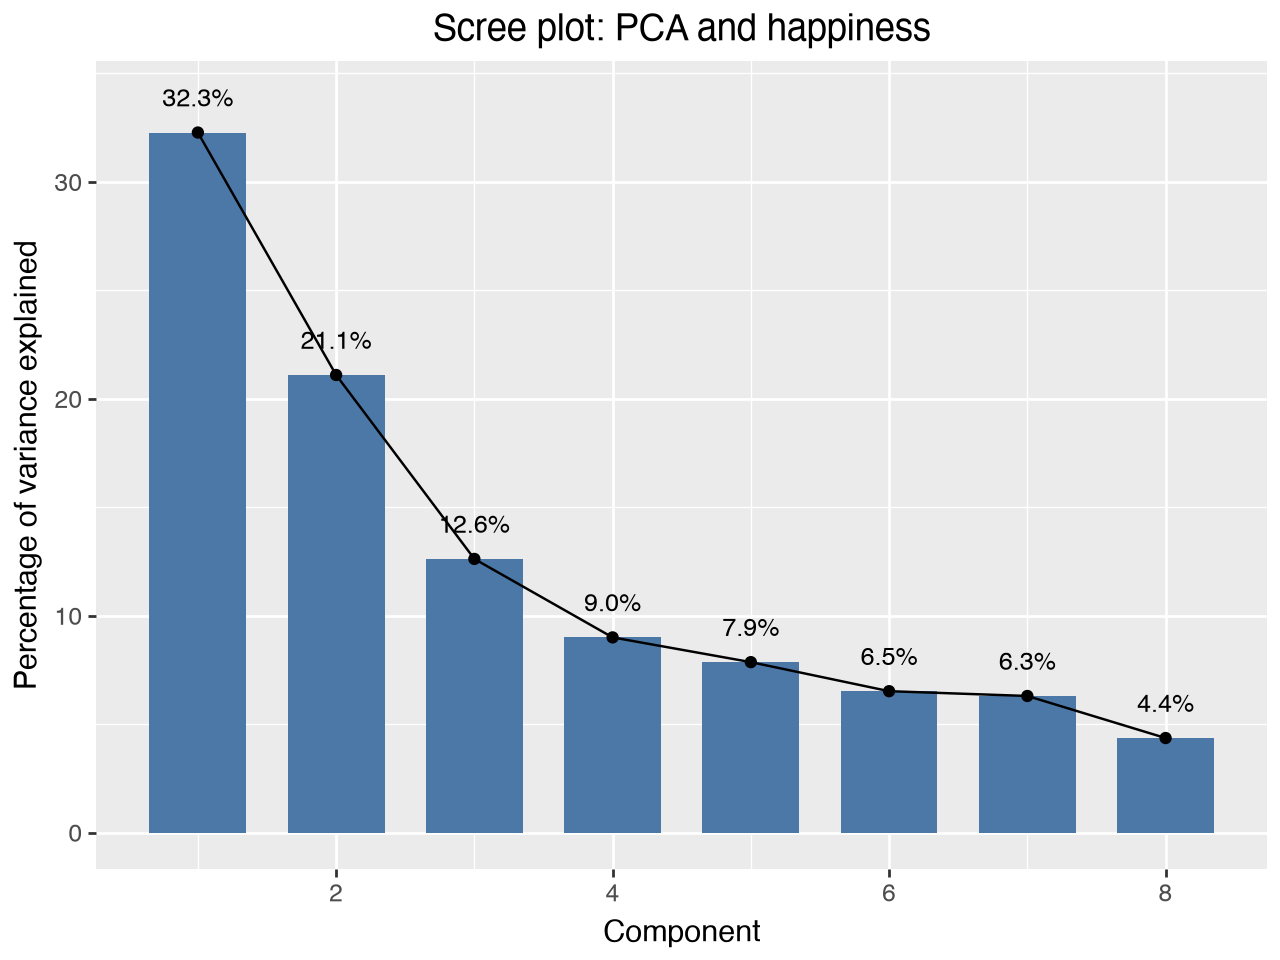

In [14]:

scree_happy = pd.DataFrame({
    'component': range(1, 9),
    'percent': prop_happy * 100
})

scree_happy['label'] = scree_happy['percent'].map(
    lambda p: f'{p:.1f}%'
)

(
    ggplot(scree_happy, aes('component', 'percent'))
    + geom_col(fill='#4C78A8', width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label='label'), nudge_y=1.6, size=9)
    + labs(
        x='Component',
        y='Percentage of variance explained',
        title='Scree plot: PCA and happiness'
    )
)

The scree plot suggests retaining three principal components, as the decline in explained variance becomes more gradual after PC3. Together, these components explain approximately 66.0% of the total variance, providing a balance between dimensionality reduction and information retention.

In [15]:

loadings_happy = pd.DataFrame(
    pca_happy.components_.T,
    index=cols_happy,
    columns=[f'PC{i}' for i in range(1, 9)]
)

print(loadings_happy.round(3))

                 PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
income_cont    0.191  0.514 -0.184 -0.339  0.725 -0.150 -0.051 -0.027
prestg10       0.234  0.545  0.061  0.184 -0.389 -0.397  0.548  0.029
educ           0.278  0.512 -0.034  0.221 -0.278  0.496 -0.535 -0.019
age           -0.006  0.099  0.975 -0.129  0.109 -0.006 -0.084 -0.066
binary_lvmus   0.505 -0.197  0.050 -0.263 -0.061  0.058  0.020  0.791
binary_artxbt  0.467 -0.193  0.040  0.136  0.223  0.544  0.513 -0.339
binary_movie   0.448 -0.193 -0.064 -0.516 -0.331 -0.279 -0.230 -0.501
binary_creat   0.396 -0.232  0.052  0.657  0.266 -0.443 -0.295 -0.035


PC1 primarily reflects cultural participation, with relatively high positive loadings on live music attendance (0.505), art exhibitions (0.467), movie attendance (0.448), and creative activities (0.396).

PC2 primarily reflects socioeconomic status, with high positive loadings on occupational prestige (0.545), income (0.514), and education (0.512). Higher PC2 scores therefore generally indicate greater socioeconomic advantage.

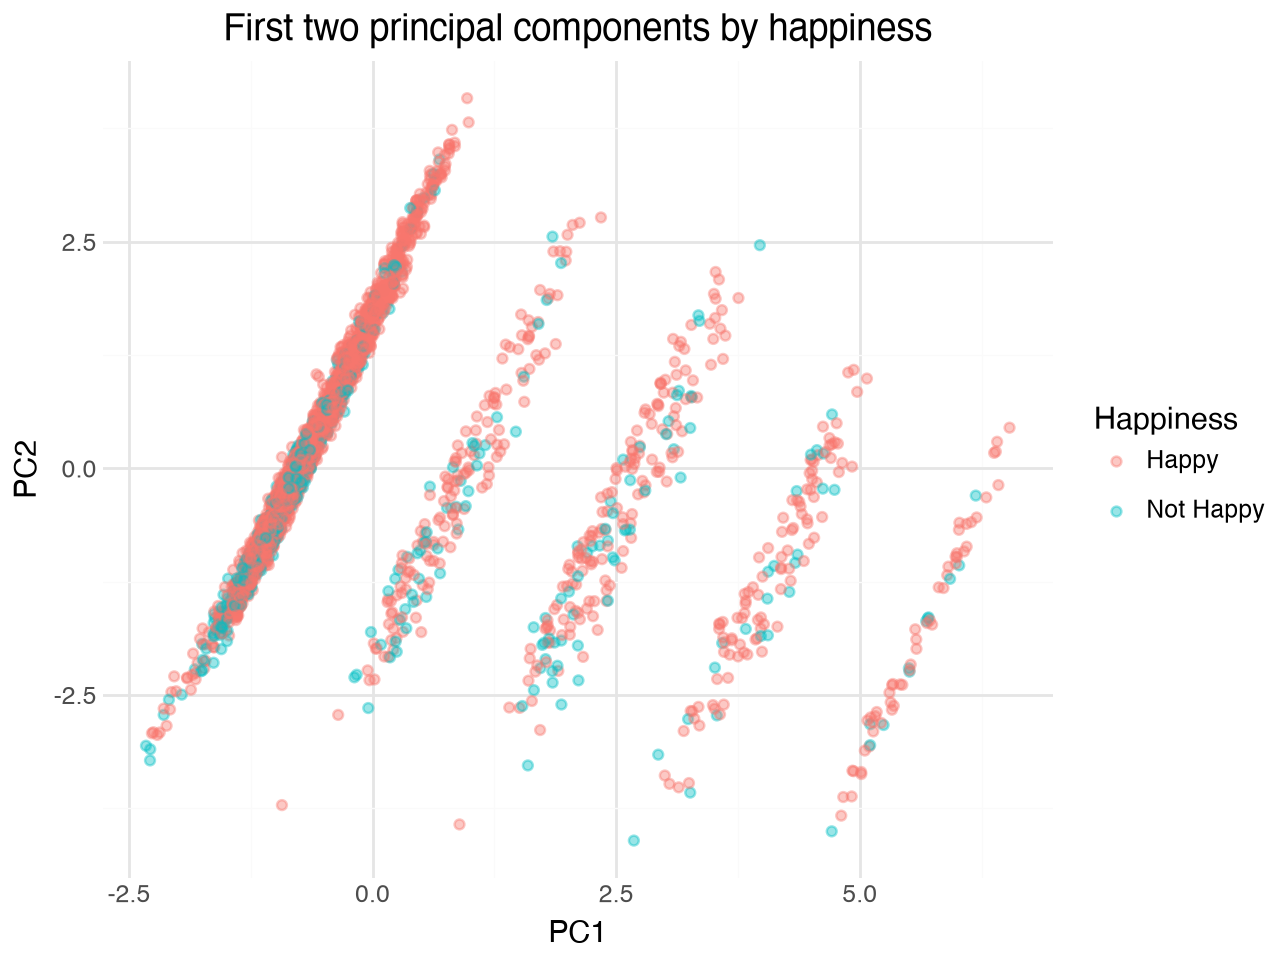

In [16]:

scores_happy = pca_happy.transform(X_happy)

plot_happy = work_happy.copy()
plot_happy['PC1'] = scores_happy[:, 0]
plot_happy['PC2'] = scores_happy[:, 1]

plot_happy['Happiness'] = np.where(
    plot_happy['happy_bin'] == 1,
    'Happy',
    'Not Happy'
)

(
    ggplot(plot_happy, aes('PC1', 'PC2', color='Happiness'))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(
        x='PC1',
        y='PC2',
        title='First two principal components by happiness'
    )
)

The scatterplot shows substantial overlap between happy and unhappy respondents across PC1 and PC2, suggesting that cultural participation and socioeconomic status do not clearly distinguish the two groups visually. Nevertheless, differences in happiness may still be statistically detectable through logistic regression.

In [17]:

# Logistic regression using PC1 and PC2
logit_happy = smf.logit(
    'happy_bin ~ PC1 + PC2',
    data=plot_happy
).fit()

print(logit_happy.summary())

# Odds ratios
print(np.exp(logit_happy.params))

Optimization terminated successfully.
         Current function value: 0.523115
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              happy_bin   No. Observations:                 2842
Model:                          Logit   Df Residuals:                     2839
Method:                           MLE   Df Model:                            2
Date:                Wed, 21 Oct 2026   Pseudo R-squ.:                 0.02946
Time:                        00:16:05   Log-Likelihood:                -1486.7
converged:                       True   LL-Null:                       -1531.8
Covariance Type:            nonrobust   LLR p-value:                 2.510e-20
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2626      0.047     27.041      0.000       1.171       1.354
PC1            0.1053      0.

In [19]:
# Updating model to include PC3
plot_happy['PC3'] = scores_happy[:, 2]

# Logistic regression using three components
logit_happy3 = smf.logit(
    'happy_bin ~ PC1 + PC2 + PC3',
    data=plot_happy
).fit()

print(logit_happy3.summary())

# Calculate odds ratios
print(np.exp(logit_happy3.params))


Optimization terminated successfully.
         Current function value: 0.522364
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              happy_bin   No. Observations:                 2842
Model:                          Logit   Df Residuals:                     2838
Method:                           MLE   Df Model:                            3
Date:                Wed, 21 Oct 2026   Pseudo R-squ.:                 0.03086
Time:                        00:21:32   Log-Likelihood:                -1484.6
converged:                       True   LL-Null:                       -1531.8
Covariance Type:            nonrobust   LLR p-value:                 2.323e-20
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2653      0.047     27.036      0.000       1.174       1.357
PC1            0.1053      0.

### Logistic Regression Interpretation

The logistic regression indicates that all three retained principal components are significantly associated with happiness.

PC1, which primarily represents cultural participation, has a positive coefficient (β = 0.105, p < 0.001). A one-unit increase in PC1 is associated with approximately 11.1% higher odds of being happy, holding the other components constant.

Similarly, PC2, which primarily represents socioeconomic status, has a positive coefficient (β = 0.321, p < 0.001). A one-unit increase in PC2 is associated with approximately 37.8% higher odds of being happy.

Conversely, PC3, which is primarily associated with age, has a negative coefficient (β = −0.092, p = 0.039). A one-unit increase in PC3 is associated with approximately 8.8% lower odds of being happy.

Although the model is statistically significant overall (likelihood-ratio p < 0.001), its relatively low pseudo R² (0.031) suggests limited explanatory power.

Overall, the findings suggest that greater cultural participation and socioeconomic advantage are positively associated with happiness, while the age-related component exhibits a modest negative association. These relationships are correlational rather than causal.